# 12 · The masked network, trained on real screens

Notebook 10's masked network - the tile search's N+1 plus a correction through a gate opened
where the search's motion leaves the change unexplained - was trained on the drawn scenes. On
real screen recordings (notebook 11) it was the one learned model ahead of the tile search: +0.24
dB on the changed tiles where N+1 is a new frame (95% over videos +0.13 to +0.32), +0.61 over
repeat. Real screens are where one motion per tile fails more often, and the drawn scenes taught
it little about how they change.

So it is trained here on real screens, two ways: **from scratch**, and **fine-tuned** from notebook
10's weights. The 81 screen videos of notebook 11 are split **by video**, within each category:
about 31 to test, never trained on and never used to choose an epoch; of the rest, 8 to choose
epochs, the others to train on. Each clip goes through the stream's downscale and codec as in
notebook 11 (24-30 fps sources, every second frame received: the frame to make is the real one
between).

Steps:

1. **The split and the data** - moving tiles cut from the training and the epoch-choosing videos.
2. **Training** - from scratch and fine-tuned.
3. **Test** - every tile of the test videos, beside repeat, the tile search, 3DRS and notebook 10's
   network; the fair test is the changed tiles where N+1 is a new frame (notebook 11, "Duplicated
   frames").

Needs: the YouTube sequences, notebook 10's checkpoint and notebook 11's raw frame steps
(`checkpoints/recorded/raw_steps.json`). Writes the tiles and the trainings to
`checkpoints/masked_real/`; nothing is exported.

In [1]:
"""Settings."""

import json
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import masked, models, recorded, recursive, training
from helpers.recursive import RecursiveSearch
from helpers.training import DEVICE

STILL, SHARPNESS, CAP = 0.1, 10.0, 50.0
PER_CLIP = {"train": 32, "val": 16}           # moving tiles cut from each clip
BATCH_SIZE, PATIENCE = 16, 4
CACHE = training.CHECKPOINT_DIR / "masked_real"
SEED = 0
training.seed_everything(SEED)

SCREENS = [
    "Cinema_4D/3N2nRlKlbgk", "Cinema_4D/3OnjlqkFClw", "Cinema_4D/6y8iPU4xTZs",
    "Cinema_4D/HuPwUlHWi7M", "Cinema_4D/Wb7GrS8csC8", "Cinema_4D/WqMNDw7zj24",
    "Cinema_4D/YMpf7sjLOsw", "Cinema_4D/YUF6yUFzZR8", "Cinema_4D/ek28bIHBxLE",
    "Cinema_4D/fI49YQ-c7Gg", "Cinema_4D/m077KW7jD_w", "Cinema_4D/zpNnUUQBgMo",
    "Computer/ldH3aBSYGW4", "Digital_painting/CyaXHJjh1E0", "Digital_painting/FpmtImp2jQE",
    "Digital_painting/anv74Y5n2BI", "Digital_painting/kbA1I_1LdLM", "Digital_painting/usj75M0UOIg",
    "Font/NBRptKep6vU", "Font/_pqbCCuxIeM", "Font/uEiWevVqYw0",
    "Map/VFotXCaAxbE", "Map/kOPj4JVxkaE", "Map/rSSVApBDxdk",
    "Map/tb0C1CO4ang", "Map/w1sWRlMQD3U", "Microsoft_Windows/0ElkyEf7bVU",
    "Microsoft_Windows/5XN1agV-pHg", "Microsoft_Windows/5l4GAZxhjkY", "Microsoft_Windows/65KCQsbVjao",
    "Microsoft_Windows/A5HBnSAZEtY", "Microsoft_Windows/EjpH5f9xv90", "Microsoft_Windows/OJzjrFRwouQ",
    "Microsoft_Windows/Tmd9TMyFdEM", "Microsoft_Windows/WqnDsSZJaRk", "Microsoft_Windows/ZyCTAVT_e6M",
    "Microsoft_Windows/gscBIcLm_Gw", "Microsoft_Windows/kVhdOWxQNF8", "Microsoft_Windows/muZ87U-unZE",
    "Microsoft_Windows/rqRovhzewks", "Microsoft_Windows/yAqsK_3gimg", "Microsoft_Windows/yw9xxpdfGbo",
    "Personal_computer/6IkVjaV-PxU", "Personal_computer/wMw8j9qoY24", "Screencast/1_iVs-exIEk",
    "Screencast/1cqdCQZ_rYw", "Screencast/5IWA6qNMiA8", "Screencast/BQldp1LelSY",
    "Screencast/gyogNNYHSuo", "Screencast/i_Vl80pJjdg", "Screencast/jH6J-n6zt4c",
    "Screencast/nAhUUivmD-Q", "Screencast/pykywx452N8", "Screencast/tGRfnsJnSTY",
    "Screenshot/_j1FKT3sdfw", "Sprite_computer_graphics/haAw7_HBc24", "Text_messaging/eYEFLv9do0k",
    "Web_page/AZITFc78-sA", "Web_page/GD9yAOho4zc", "Web_page/QdZj6wYAtZs",
    "Web_page/lrIYoUJqu44", "Web_page/q6CBH_TKEuE", "Website/15qRSwJ6uso",
    "Website/Hh3ms730O1o", "Website/IBA-dN_pSH8", "Website/IdZ8_S0ptJg",
    "Website/VVxYUNZ8u8U", "Website/aP-pZIQs6yE", "Website/md5YK_CxD3s",
    "Website/wCSTWjZ31iA", "Website/xNmwZ1rholY", "Computer/DyS-XDmfjmM",
    "Digital_painting/YUwbMpIbz-w", "Font/JxOaKvheZms", "Microsoft_Windows/1u954QeRdFE",
    "Microsoft_Windows/jKMgt_ugvH0", "Personal_computer/aZeEqvaJzus", "Personal_computer/zqCPKnzmcYA",
    "Sprite_computer_graphics/gmaQQmRPeeM", "Text_messaging/bkoMyKY_cAY", "Web_page/MmNPG0Gn6lc",
]


def split_by_video(videos, share, seed):
    """Per category, a seeded `share` of its videos (at least one where it has two or more) - the rest apart."""
    rng = np.random.default_rng(seed)
    chosen, rest = [], []
    for category in sorted({v.split("/")[0] for v in videos}):
        items = sorted(v for v in videos if v.startswith(category + "/"))
        rng.shuffle(items)
        count = int(round(share * len(items))) if len(items) > 1 else 0
        chosen += items[:count]
        rest += items[count:]
    return chosen, rest


TEST, REST = split_by_video(SCREENS, 31 / 81, SEED)
VAL, TRAIN = split_by_video(REST, 8 / 50, SEED + 1)
manifest = recorded.manifest({"train": TRAIN, "val": VAL, "test": TEST}, seed=SEED)
for name, items in (("train", TRAIN), ("val", VAL), ("test", TEST)):
    print(f"{name:<6} {len(items):3} videos, {len(manifest['splits'][name]['sources']):4} clips")
assert not set(TEST) & set(TRAIN + VAL)

FRACTION = 1 / manifest["received_every"]


def tile_search():
    return models.TileSearch(4, 2, SHARPNESS, 2, FRACTION, still=STILL)


published = tile_search().to(DEVICE).eval()
pyramid = models.PyramidSearch(((4, 4, 1), (2, 1, 2), (1, 2, 4)), SHARPNESS, FRACTION, STILL, "equiangular",
                               whole=True).to(DEVICE).eval()
drawn_state = torch.load(training.CHECKPOINT_DIR / "masked_runs" / "masked_gated.pt", map_location="cpu",
                         weights_only=False)["progress"]["best"]["state"]

train   42 videos,  210 clips
val      7 videos,   35 clips
test    32 videos,  160 clips


## 1. The data

From each training clip up to 32 tiles where the published search's gate is open, from each
epoch-choosing clip up to 16 - frames N−2, N and N+1 each (`masked.build`). Screen videos repeat
frames (notebook 11), and the tiles keep them: a network that learns real screens has to learn
those too.

In [2]:
CACHE.mkdir(parents=True, exist_ok=True)
tiles = {}
for split, per_clip in PER_CLIP.items():
    started = time.time()
    path = CACHE / f"tiles_{split}"
    tiles[split] = masked.load(None, path) or masked.build(manifest, split, published, per_clip, seed=SEED, path=path)
    frames, meta = tiles[split]
    print(f"{split}: {len(frames)} moving tiles from {len(set(meta['source']))} clips "
          f"({frames.nbytes / 1e9:.1f} GB, {time.time() - started:.0f}s)")

train: 5245 moving tiles from 200 clips (2.9 GB, 142s)
val: 499 moving tiles from 35 clips (0.3 GB, 20s)


## 2. Training

As in notebook 10: Adam, batches of 16 whole tiles, `metrics.luma_chroma_l1` over the window less
the halo; an epoch is kept if it beats the best so far on the epoch-choosing tiles (moving,
capped at 50 dB), and the learning rate halves after 4 epochs without. **From scratch** starts
as the search (the correction at zero) at 1e-3; **fine-tuned** starts from notebook 10's network
at 3e-4. Epoch 0 counts as the first best: the search for one, notebook 10's network for the
other.


from scratch
untrained (the search): 45.566 dB on the moving validation tiles, capped
epoch 1: loss 0.00712, 45.566 dB, lr 1.0e-03, gate a, b -0.04, -0.03, 6s
epoch 2: loss 0.00697, 45.566 dB, lr 1.0e-03, gate a, b -0.05, -0.05, 5s
epoch 3: loss 0.00697, 45.566 dB, lr 1.0e-03, gate a, b -0.07, -0.08, 5s
epoch 4: loss 0.00699, 45.566 dB, lr 1.0e-03, gate a, b -0.10, -0.11, 5s
epoch 5: loss 0.00695, 45.566 dB, lr 5.0e-04, gate a, b -0.11, -0.12, 5s
epoch 6: loss 0.00693, 45.566 dB, lr 5.0e-04, gate a, b -0.12, -0.13, 5s
epoch 7: loss 0.00697, 45.566 dB, lr 5.0e-04, gate a, b -0.13, -0.15, 5s
epoch 8: loss 0.00696, 45.566 dB, lr 5.0e-04, gate a, b -0.14, -0.17, 5s
epoch 9: loss 0.00696, 45.566 dB, lr 2.5e-04, gate a, b -0.15, -0.17, 6s
epoch 10: loss 0.00693, 45.566 dB, lr 2.5e-04, gate a, b -0.15, -0.18, 6s
epoch 11: loss 0.00695, 45.566 dB, lr 2.5e-04, gate a, b -0.16, -0.19, 5s
epoch 12: loss 0.00696, 45.566 dB, lr 2.5e-04, gate a, b -0.16, -0.19, 5s
epoch 13: loss 0.00696, 45.566 dB,

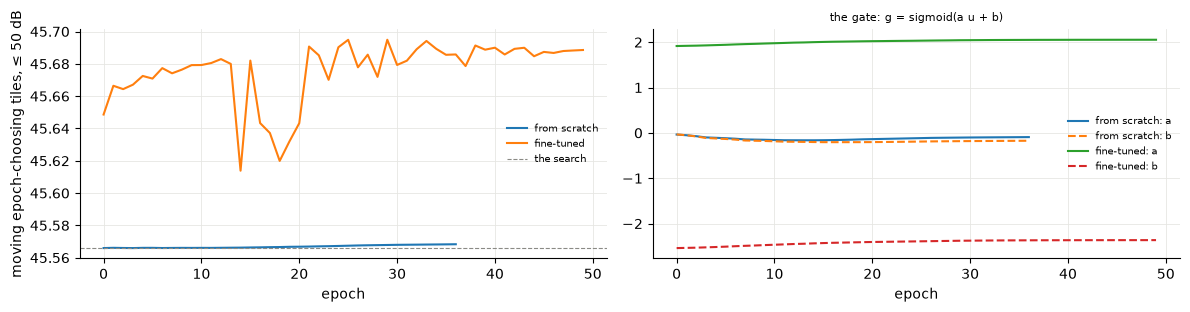

from scratch: gate g = 0.46 where the search explains everything, 0.43 where it explains nothing
fine-tuned: gate g = 0.08 where the search explains everything, 0.41 where it explains nothing


In [3]:
def masked_network(state=None):
    network = models.Masked(tile_search(), gated=True).to(DEVICE)
    if state is not None:
        network.load_state_dict(state)
    return network


RUNS = {"from scratch": (None, 1e-3), "fine-tuned": (drawn_state, 3e-4)}
networks, histories, bests = {}, {}, {}
for name, (state, rate) in RUNS.items():
    print(f"\n{'=' * 90}\n{name}\n{'=' * 90}")
    training.seed_everything(SEED)
    networks[name] = masked_network(state)
    histories[name], bests[name] = masked.train(networks[name], tiles["train"][0], tiles["val"],
                                                CACHE / f"{name.replace(' ', '_').replace('-', '_')}.pt", rate,
                                                BATCH_SIZE, PATIENCE)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for name, found in histories.items():
    axes[0].plot([h["score"] for h in found], label=name)
    gates = np.array([h["gate"] for h in found])
    axes[1].plot(gates[:, 0], label=f"{name}: a")
    axes[1].plot(gates[:, 1], ls="--", label=f"{name}: b")
search_model = models.Motion(search=published, learned=False).to(DEVICE).eval()
axes[0].axhline(np.minimum(masked.scores(search_model, *tiles["val"]), CAP).mean(), color="#8a8a85", ls="--", lw=0.8,
                label="the search")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("moving epoch-choosing tiles, ≤ 50 dB")
axes[1].set_xlabel("epoch")
axes[1].set_title("the gate: g = sigmoid(a u + b)", fontsize=8)
for ax in axes:
    ax.legend(fontsize=7, frameon=False)
    ax.grid(color="#e6e6e3", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()
for name, network in networks.items():
    a, b = network.gate.detach().cpu().tolist()
    print(f"{name}: gate g = {1 / (1 + np.exp(-b)):.2f} where the search explains everything, "
          f"{1 / (1 + np.exp(-(a + b))):.2f} where it explains nothing")

## 3. Test

Every client tile of every test clip at every received frame, all methods on the same frames
(`recursive.load`). The columns of notebook 11: the changed tiles, all, the moving ones capped at
50 dB with the gain over the published search and its 95% range over **videos**, and the moving
tiles with the stop decided perfectly. Then the fair test - the changed tiles where N+1 is a new
frame in the raw source - with each method's gain over repeat and over the tile search.

In [4]:
def as_picture(model):
    model = model.to(DEVICE).eval()
    return lambda previous, current, target: model(previous, current)


PICTURES = {"repeat": lambda previous, current, target: current,
            "published search": as_picture(search_model),
            "pyramid, whole-pixel (notebook 8)": as_picture(models.Motion(search=pyramid, learned=False)),
            "masked, drawn scenes (notebook 10)": as_picture(masked_network(drawn_state)),
            "masked, real screens from scratch": as_picture(networks["from scratch"]),
            "masked, real screens fine-tuned": as_picture(networks["fine-tuned"])}
FIELDS = {"3DRS (notebook 9)": RecursiveSearch(16, 3, 16, seeds=("tile", "minima", "blocks"))}
ORDER = ["repeat", "published search", "pyramid, whole-pixel (notebook 8)", "3DRS (notebook 9)",
         "masked, drawn scenes (notebook 10)", "masked, real screens from scratch", "masked, real screens fine-tuned"]
path = CACHE / "test.pkl"
newest = max((CACHE / f"{name.replace(' ', '_').replace('-', '_')}.pt").stat().st_mtime for name in RUNS)
if path.exists() and path.stat().st_mtime > newest:
    test = pickle.loads(path.read_bytes())
else:
    started = time.time()
    test = recursive.load(manifest, "test", FIELDS, PICTURES, published, pyramid, STILL, start=1)
    path.write_bytes(pickle.dumps(test))
    print(f"{len(test['tiles']['source'])} tiles in {time.time() - started:.0f}s")

table = test["tiles"]
sources = manifest["splits"]["test"]["sources"]
video_of = np.array([sources[s]["video"] for s in table["source"]])
moving, changed = table["moving"], table["changed"]
steps = json.loads((training.CHECKPOINT_DIR / "recorded" / "raw_steps.json").read_text())
fresh = np.array([n + 1 < len(steps[sources[s]["file"]]) and steps[sources[s]["file"]][n] > 0.25
                  and steps[sources[s]["file"]][n + 1] > 0.25 for s, n in zip(table["source"], table["frame"])])
rng = np.random.default_rng(SEED)


def over_videos(gain, mask, draws=2000):
    per = [gain[mask & (video_of == v)] for v in np.unique(video_of[mask])]
    means = [np.concatenate([per[i] for i in rng.integers(0, len(per), len(per))]).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])


def capped(name):
    return np.minimum(test["wpsnr"][name], CAP)


BASE = "published search"
print(f"{len(moving)} tiles from {len(set(video_of))} test videos: {moving.mean():.0%} moving, {changed.mean():.0%} changed, "
      f"{(changed & fresh).sum()} changed with N+1 a new frame\n")
print(f"{'wPSNR (dB)':<38}{'changed':>16}{'all':>16}{'moving, ≤ 50 dB':>18}{'95% over videos':>18}{'perfect stop':>14}")
for name in ORDER:
    s, base = test["wpsnr"][name], test["wpsnr"][BASE]
    gain = capped(name) - capped(BASE)
    low, high = over_videos(gain, moving) if name != BASE else (0, 0)
    stop = np.maximum(capped(name), capped("repeat"))[moving].mean()
    print(f"{name:<38}{s[changed].mean():8.2f} ({s[changed].mean() - base[changed].mean():+5.2f})"
          f"{s.mean():8.2f} ({s.mean() - base.mean():+5.2f})"
          f"{capped(name)[moving].mean():10.2f} ({gain[moving].mean():+5.2f})  [{low:+.2f}, {high:+.2f}]{stop:14.2f}")

pick = changed & fresh
print(f"\nchanged tiles where N+1 is a new frame: {pick.sum()} tiles from {len(set(video_of[pick]))} videos")
print(f"{'':<38}{'wPSNR':>8}{'over repeat':>14}{'95% over videos':>18}{'over the search':>17}{'95% over videos':>18}"
      f"{'tiles better / worse than the search':>40}")
for name in ORDER:
    s = test["wpsnr"][name]
    over_repeat, over_search = s - test["wpsnr"]["repeat"], s - test["wpsnr"][BASE]
    lr, hr = over_videos(over_repeat, pick) if name != "repeat" else (0, 0)
    ls, hs = over_videos(over_search, pick) if name != BASE else (0, 0)
    better, worse = (over_search[pick] > 0.05).mean(), (over_search[pick] < -0.05).mean()
    print(f"{name:<38}{s[pick].mean():8.2f}{over_repeat[pick].mean():+14.2f}   [{lr:+.2f}, {hr:+.2f}]"
          f"{over_search[pick].mean():+15.2f}   [{ls:+.2f}, {hs:+.2f}]{better:>28.0%} / {worse:.0%}")

13350 tiles in 161s
13350 tiles from 32 test videos: 50% moving, 19% changed, 1243 changed with N+1 a new frame

wPSNR (dB)                                     changed             all   moving, ≤ 50 dB   95% over videos  perfect stop
repeat                                   33.46 (+0.07)   62.87 (+0.32)     43.92 (+0.37)  [+0.17, +0.62]         43.92
published search                         33.39 (+0.00)   62.55 (+0.00)     43.54 (+0.00)  [+0.00, +0.00]         44.04
pyramid, whole-pixel (notebook 8)        33.38 (-0.01)   62.51 (-0.04)     43.41 (-0.13)  [-0.25, -0.02]         44.09
3DRS (notebook 9)                        33.32 (-0.07)   61.91 (-0.64)     42.81 (-0.73)  [-1.03, -0.47]         44.24
masked, drawn scenes (notebook 10)       33.46 (+0.07)   62.38 (-0.17)     43.59 (+0.05)  [+0.00, +0.10]         44.08
masked, real screens from scratch        33.37 (-0.02)   62.53 (-0.02)     43.54 (+0.00)  [+0.00, +0.01]         44.04
masked, real screens fine-tuned          33.47 (+0.0

## What it says

- **Trained on real screens from scratch, the network learns nothing.** On the epoch-choosing
  videos it ends +0.002 dB over the search; its loss hardly moves. On the test videos it is the
  search to a hundredth of a dB on the moving tiles, and −0.05 dB on the changed tiles where N+1
  is a new frame (95% over videos −0.19 to +0.01). Its gate stays near ½ everywhere, with nothing
  much behind it.
- **Fine-tuned from the drawn scenes, it learns to be quieter, not better.** On the moving test
  tiles it is +0.15 dB over the search (+0.08 to +0.23) against the drawn-scene network's +0.05:
  it damages less where nothing really changes, which is what the epoch-choosing score rewards.
  On the fair test - the changed tiles where N+1 is new - it is +0.07 dB over the search (−0.38 to
  +0.32), against the drawn-scene network's +0.16 (−0.10 to +0.30). No better, and less often
  better (21% of those tiles against 52%).
- **Repeat still leads where it matters least.** On every moving test tile it is +0.37 dB over the
  search (+0.17 to +0.62) and ahead of every method: most moving tiles on these screens are a still
  picture under YouTube's and the stream's codec noise, where any guess costs.
- **3DRS is the one method ahead on the fair test**: +0.60 dB over the search where N+1 is new
  (+0.29 to +0.92), +0.84 over repeat - as in notebook 11, and as there, −0.73 on the moving tiles
  overall, where it finds motion in codec noise.
- **Why training on real screens did not help.** The 42 training videos give 5,245 moving tiles,
  most of them a still screen whose pixels the codec stirs; the changes worth learning - a new
  frame with something in it that moved - are a small part, and on screens they are mostly not
  motion: annotations, highlights, fades, redraws, which two frames do not foretell. The loss is
  spent on noise, and the safe answer to noise is to stay quiet. And the test is small: 1,243
  changed tiles with a new N+1, from 18 videos; every range above is wide.

So the masked network is not worth training on this material: the drawn scenes taught it a
little more about motion than real tutorials can, and neither is worth its fourteen times the
search's work. What real screens reward is not drawing at all where nothing moved, and moving
per block where something did - which is a gate and 3DRS, not a network: the place to look next.